# Baseline e comparação de modelos

O treino oficial está em `src/churn/train.py` (`python -m churn.train`). Este notebook só analisa o baseline e os resultados gravados em `docs/experiments/`. O conjunto de teste não é tocado aqui.

In [1]:
import json

import joblib
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.model_selection import (StratifiedKFold, cross_val_predict, cross_validate,
                                     train_test_split)

from churn.config import SEED, TEST_SIZE
from churn.data import load_dataset
from churn.evaluate import THRESHOLD_GRID, net_value
from churn.models import build_pipeline

import matplotlib.pyplot as plt

NO_CHURN, CHURN, MUTED = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": "#bdbcb6", "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.grid": True, "grid.color": "#e8e7e3",
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.axisbelow": True,
})

X, y = load_dataset()
X_train, _, y_train, _ = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED
)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

## 1. Métricas

- **Técnica principal: AUC-ROC.** Mede a capacidade de ordenar clientes por risco, sem depender de limiar. A PR-AUC complementa, por ser mais sensível à classe rara.
- **Negócio: valor líquido da campanha por 1.000 clientes.** Ofertar retenção custa 50 por cliente. Um cliente que cancelaria é retido com probabilidade de 30%, preservando 12 mensalidades. **Esses três valores são premissas ilustrativas**, pois o dataset não os informa.

## 2. Baseline: regressão logística com hiperparâmetros padrão

In [2]:
baseline = build_pipeline(LogisticRegression(max_iter=2000, random_state=SEED))
scores = cross_validate(baseline, X_train, y_train, cv=cv,
                        scoring=["roc_auc", "average_precision", "f1"])
for metric in ["roc_auc", "average_precision", "f1"]:
    values = scores[f"test_{metric}"]
    print(f"{metric:>18}: {values.mean():.3f} ± {values.std():.3f}")

oof = cross_val_predict(baseline, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
print(classification_report(y_train, oof >= 0.5, target_names=["Permaneceu", "Cancelou"]))

           roc_auc: 0.846 ± 0.013
 average_precision: 0.661 ± 0.019
                f1: 0.592 ± 0.030


              precision    recall  f1-score   support

  Permaneceu       0.84      0.90      0.87      4139
    Cancelou       0.65      0.54      0.59      1495

    accuracy                           0.80      5634
   macro avg       0.75      0.72      0.73      5634
weighted avg       0.79      0.80      0.80      5634



**Leitura.** No limiar padrão de 0,5, o baseline deixa passar parte relevante de quem cancela, como mostra o recall da classe `Cancelou`. Por isso o limiar é tratado como uma decisão de negócio na seção 4.

## 3. Comparação entre modelos

Validação cruzada aninhada (5 folds externos, 3 internos) somente no treino. Como cada modelo é ajustado dentro do fold, a busca de hiperparâmetros não contamina a estimativa de desempenho.

In [3]:
comparison = pd.read_csv("../docs/experiments/model_comparison.csv", index_col="model")
comparison

,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,brier_mean,f1_at_0.5,threshold,f1,precision,recall,flagged_rate,net_value_per_1000
model,,,,,,,,,,,,
dummy,0.5000,0.0000,0.2654,0.0001,0.1949,0.0000,0.05,0.4194,0.2654,1.0000,1.0000,21511.7891
logistic_regression,0.8464,0.0143,0.6608,0.0208,0.1349,0.5977,0.26,0.6302,0.5165,0.8080,0.4152,39278.2038
random_forest,0.8474,0.0100,0.6619,0.0202,0.1352,0.5677,0.19,0.6050,0.4564,0.8970,0.5215,39150.2201
mlp,0.8399,0.0153,0.6475,0.0248,0.1379,0.5856,0.19,0.6064,0.4685,0.8595,0.4869,38443.3404


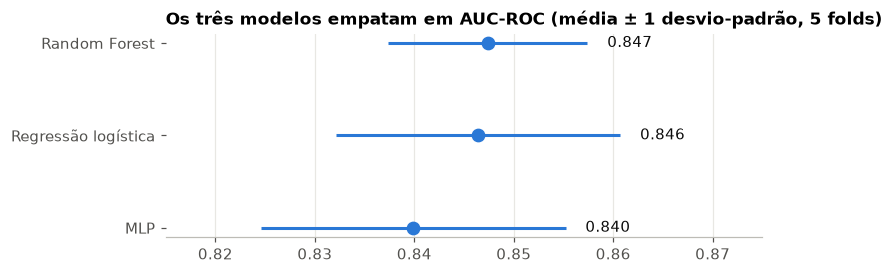

In [4]:
order = ["mlp", "logistic_regression", "random_forest"]
labels = {"mlp": "MLP", "logistic_regression": "Regressão logística",
          "random_forest": "Random Forest"}
subset = comparison.loc[order]
fig, ax = plt.subplots(figsize=(7, 2.4))
ax.errorbar(subset["roc_auc_mean"], [labels[m] for m in order], xerr=subset["roc_auc_std"],
            fmt="o", markersize=8, color=NO_CHURN, elinewidth=2, capsize=0)
for position, (mean, std) in enumerate(zip(subset["roc_auc_mean"], subset["roc_auc_std"])):
    ax.text(mean + std + 0.002, position, f"{mean:.3f}", va="center", color="#0b0b0b")
ax.set_title("Os três modelos empatam em AUC-ROC (média ± 1 desvio-padrão, 5 folds)")
ax.set_xlim(0.815, 0.875)
ax.grid(axis="y", visible=False)
fig.savefig("../docs/figures/model_comparison.png")
plt.show()

**Escolha do campeão.** A regra, definida em `churn.evaluate.select_champion`, é: entre os modelos a até um desvio-padrão do melhor, ficar com o mais simples.

A Random Forest teve a maior AUC (0,847), mas a regressão logística (0,846) está dentro da margem, e a MLP (0,840) também. **A regressão logística vence**: é mais barata, mais fácil de explicar à diretoria e ainda teve o maior valor líquido na validação. Modelos mais complexos não trouxeram ganho mensurável neste dataset.

## 4. Limiar de decisão

O limiar é escolhido com predições fora da amostra do treino, sem usar o teste.

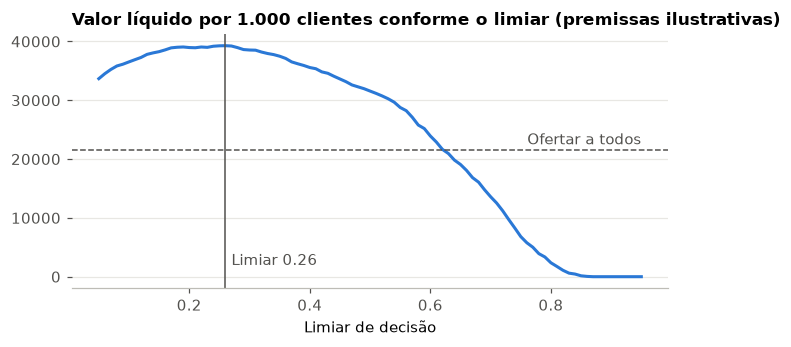

In [5]:
artifact = joblib.load("../models/champion.joblib")
metadata = artifact["metadata"]
champion = build_pipeline(LogisticRegression(C=10.0, max_iter=2000, random_state=SEED))
proba = cross_val_predict(champion, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
monthly = X_train["MonthlyCharges"]
per_1000 = 1000 / len(y_train)
values = [net_value(y_train, proba >= t, monthly) * per_1000 for t in THRESHOLD_GRID]
everyone = net_value(y_train, np.ones(len(y_train)), monthly) * per_1000

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(THRESHOLD_GRID, values, color=NO_CHURN, linewidth=2)
ax.axhline(everyone, color=MUTED, linewidth=1, linestyle="--")
ax.text(0.95, everyone + 1000, "Ofertar a todos", ha="right", color=MUTED)
ax.axvline(metadata["threshold"], color=MUTED, linewidth=1)
ax.text(metadata["threshold"] + 0.01, 2000, f"Limiar {metadata['threshold']:.2f}", color=MUTED)
ax.set_title("Valor líquido por 1.000 clientes conforme o limiar (premissas ilustrativas)")
ax.set_xlabel("Limiar de decisão")
ax.grid(axis="x", visible=False)
fig.savefig("../docs/figures/threshold_value.png")
plt.show()

**Leitura.** A curva é plana perto do máximo (entre cerca de 0,17 e 0,30), então o valor exato do limiar não é crítico. Qualquer ponto dessa faixa supera ofertar a todos.

## 5. O que move o modelo campeão

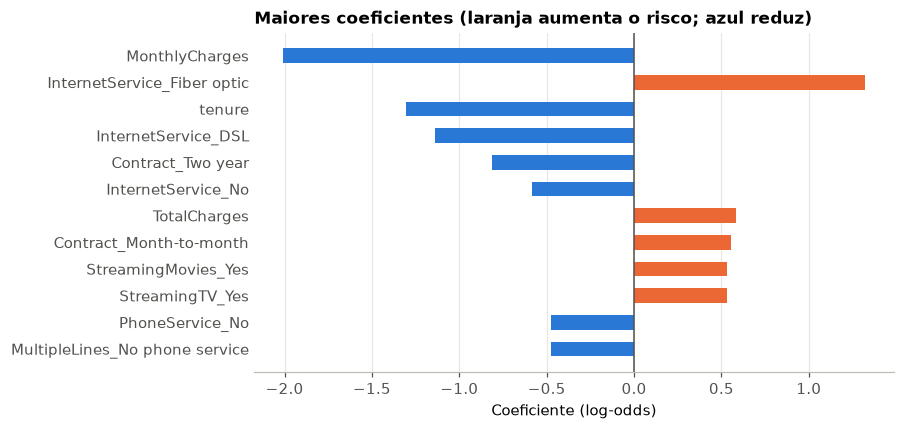

In [6]:
pipeline = artifact["pipeline"]
names = pipeline.named_steps["preprocess"].get_feature_names_out()
coefficients = pd.Series(pipeline.named_steps["model"].coef_[0], index=names)
coefficients.index = coefficients.index.str.replace(r"^\w+?__", "", regex=True)
# `No internet service` repete a mesma informação em seis colunas: fica só `InternetService_No`.
coefficients = coefficients[~coefficients.index.str.endswith("_No internet service")]
top = coefficients.reindex(coefficients.abs().sort_values().index).tail(12)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.barh(top.index, top.values, height=0.55,
        color=[CHURN if value > 0 else NO_CHURN for value in top.values])
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_title("Maiores coeficientes (laranja aumenta o risco; azul reduz)")
ax.set_xlabel("Coeficiente (log-odds)")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
fig.savefig("../docs/figures/coefficients.png")
plt.show()

**Cuidado na leitura.** Os coeficientes indicam associação, não causa, e não devem ser lidos como efeito isolado. O exemplo mais claro é `MonthlyCharges`: o coeficiente é negativo, embora o EDA mostre que quem paga mais cancela mais. Isso ocorre porque a mensalidade é quase determinada pelos serviços contratados, que também estão no modelo. Logo, o gráfico **não** significa que aumentar o preço reduz o churn.

## 6. Atributos sensíveis fazem falta?

Teste no treino: retirar `gender` e `SeniorCitizen` muda a AUC-ROC?

In [7]:
from sklearn.compose import ColumnTransformer

from churn.config import CATEGORICAL_FEATURES, NUMERIC_FEATURES
from churn.models import build_preprocessor

SENSITIVE = ["gender", "SeniorCitizen"]

def auc_without(dropped):
    categorical = [c for c in CATEGORICAL_FEATURES if c not in dropped]
    preprocess = build_preprocessor().set_params(
        transformers=[("numeric", build_preprocessor().transformers[0][1], NUMERIC_FEATURES),
                      ("categorical", build_preprocessor().transformers[1][1], categorical)]
    )
    model = build_pipeline(LogisticRegression(C=10.0, max_iter=2000, random_state=SEED))
    model.set_params(preprocess=preprocess)
    return cross_validate(model, X_train, y_train, cv=cv, scoring="roc_auc")["test_score"]

full, reduced = auc_without([]), auc_without(SENSITIVE)
print(f"Com todas as features:   {full.mean():.4f} ± {full.std():.4f}")
print(f"Sem gender/SeniorCitizen: {reduced.mean():.4f} ± {reduced.std():.4f}")

Com todas as features:   0.8464 ± 0.0128
Sem gender/SeniorCitizen: 0.8465 ± 0.0131


## 7. Resultado final do campeão no teste

Calculado uma única vez por `churn.train`.

In [8]:
pd.Series({k: v for k, v in metadata["test_metrics"].items() if isinstance(v, float)}).round(3)

roc_auc                                 0.841
pr_auc                                  0.628
brier                                   0.139
threshold                               0.260
f1                                      0.616
precision                               0.503
recall                                  0.794
flagged_rate                            0.419
net_value_per_1000                  36605.067
churn_rate_test                         0.265
net_value_flag_everyone_per_1000    19534.166
dtype: float64

In [9]:
pd.read_csv("../docs/experiments/subgroup_metrics.csv")

,group,value,n,churn_rate,roc_auc,recall,precision,flagged_rate
0,gender,Female,687,0.2809,0.8364,0.7876,0.5241,0.4221
1,gender,Male,722,0.2507,0.8469,0.8011,0.4817,0.4169
2,SeniorCitizen,No,1187,0.2325,0.8419,0.7464,0.4703,0.3690
3,SeniorCitizen,Yes,222,0.4414,0.7815,0.9286,0.5948,0.6892
4,Dependents,No,978,0.3098,0.8248,0.8284,0.5050,0.5082
5,Dependents,Yes,431,0.1647,0.8552,0.6479,0.4894,0.2181
6,Contract,Month-to-month,773,0.4256,0.7421,0.8784,0.5179,0.7219
7,Contract,One year,300,0.1200,0.7381,0.2222,0.2424,0.1100
8,Contract,Two year,336,0.0268,0.7611,0.0000,0.0000,0.0000
